# Logarithms as a counting tool

A useful way to think about a logarithm is:

> **A logarithm counts multiplicative steps.**

For example,

$$\log_2(8) = 3$$

because starting from $1$, multiplying by $2$ three times gets us to $8$:

$$1 \to 2 \to 4 \to 8$$

So:

- exponents answer: **"what number do I get after repeated multiplication?"**
- logarithms answer: **"how many repeated multiplications were needed?"**

That makes logarithms the inverse language of exponents.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')


def powers_table(base, start_exp, end_exp):
    exponents = list(range(start_exp, end_exp + 1))
    values = [base**exp for exp in exponents]
    return pd.DataFrame({
        'exponent': exponents,
        f'{base}^exponent': values,
        f'log_{base}(value)': exponents,
    })

## 1. A visual framework: additive world vs multiplicative world

Think of two number lines:

- In the **additive world**, moving right by the same amount means adding the same number each time.
- In the **multiplicative world**, moving right by the same amount in log-space means multiplying by the same factor each time.

For base $2$, equal log steps correspond to:

$$1, 2, 4, 8, 16, 32, \dots$$

Each step adds $1$ to the logarithm, but multiplies the original number by $2$.

That is the key visual idea:

$$\text{equal distances in log-space} \iff \text{equal multiplication in ordinary space}$$

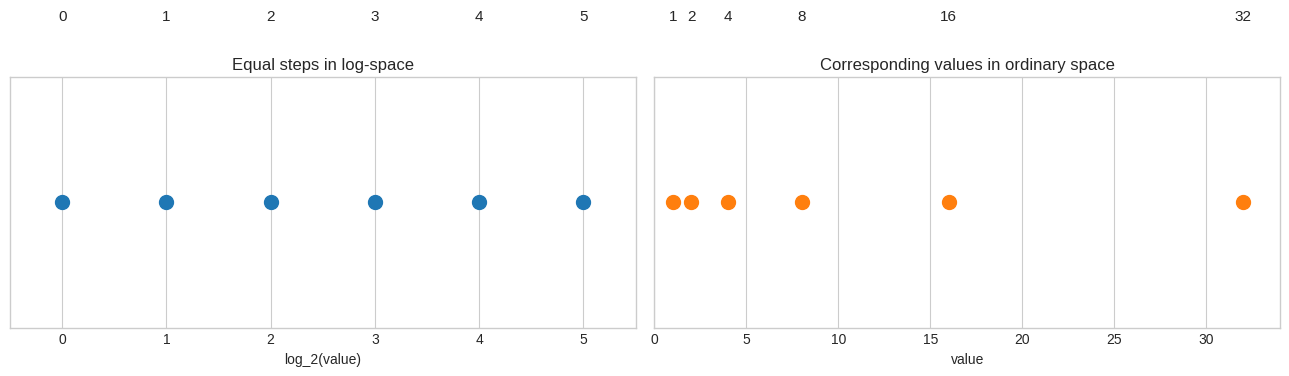

,exponent,2^exponent,log_2(value)
0,0,1,0
1,1,2,1
2,2,4,2
3,3,8,3
4,4,16,4
5,5,32,5


In [2]:
base = 2
exponents = np.arange(0, 6)
values = base ** exponents

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(exponents, np.zeros_like(exponents), s=100, color='tab:blue')
for exp in exponents:
    axes[0].text(exp, 0.08, f'{exp}', ha='center', fontsize=11)
axes[0].set_title('Equal steps in log-space')
axes[0].set_yticks([])
axes[0].set_xlabel('log_2(value)')
axes[0].set_xlim(-0.5, 5.5)

axes[1].scatter(values, np.zeros_like(values), s=100, color='tab:orange')
for value in values:
    axes[1].text(value, 0.08, f'{value}', ha='center', fontsize=11)
axes[1].set_title('Corresponding values in ordinary space')
axes[1].set_yticks([])
axes[1].set_xlabel('value')
axes[1].set_xlim(0, 34)

plt.tight_layout()
plt.show()

powers_table(2, 0, 5)

## 2. Why the log rules feel natural

Once you see a logarithm as a **counter of multiplicative steps**, the standard rules become almost unavoidable.

### Multiplication rule

$$\log_b(xy) = \log_b(x) + \log_b(y)$$

Reason:

- $\log_b(x)$ counts how many base-$b$ steps get you to $x$.
- $\log_b(y)$ counts how many more base-$b$ steps get you to $y$.
- Multiplying $x$ and $y$ combines those multiplicative journeys, so the step counts add.

### Power rule

$$\log_b(x^k) = k\log_b(x)$$

Reason:

- raising to a power repeats the same multiplicative pattern $k$ times
- repeating the same step count $k$ times multiplies the count by $k$

### Identity rule

$$\log_b(b) = 1$$

because one multiplication by $b$ takes you from $1$ to $b$.

### Zero rule

$$\log_b(1) = 0$$

because zero multiplications are needed to stay at $1$.

### Reciprocal base rule

$$\log_a(b) = \frac{1}{\log_b(a)}$$

Reason:

- if it takes many small base-$a$ steps to reach $b$, then one base-$b$ step contains that many base-$a$ steps
- turning the question around flips the unit, so the answer becomes a reciprocal

Example:

$$\log_2(8) = 3 \quad \text{and} \quad \log_8(2) = \frac{1}{3}$$

### Change of base rule

$$\log_b(x) = \frac{\log_c(x)}{\log_c(b)}$$

The most useful intuition is: **change of base is just unit conversion for multiplicative steps.**

Think of:

- $\log_c(x)$ as: "how many $c$-steps does it take to reach $x$?"
- $\log_c(b)$ as: "how many $c$-steps are packed into one $b$-step?"

So if you already know the distance to $x$ measured in $c$-steps, and you know how large one $b$-step is in that same unit, then

$$\frac{\text{total number of } c\text{-steps to }x}{\text{number of } c\text{-steps in one } b\text{-step}} = \text{number of } b\text{-steps to }x$$

That quotient is exactly $\log_b(x)$.

A concrete example:

$$\log_2(64) = \frac{\log_4(64)}{\log_4(2)}$$

Here:

- $\log_4(64) = 3$ because $4^3 = 64$
- $\log_4(2) = \tfrac{1}{2}$ because $4^{1/2} = 2$

So:

$$\log_2(64) = \frac{3}{1/2} = 6$$

Interpretation:

- it takes $3$ jumps of size $4$ to get to $64$
- each jump of size $4$ is the same as $2$ jumps of size $2$
- so altogether it takes $3 \times 2 = 6$ jumps of size $2$

That is the change-of-base rule in plain language: **count in whatever base is convenient, then convert the unit of counting.**

## 2A. Intuition for the change-of-base rule

The cleanest way to think about change of base is as a **unit conversion**.

A logarithm counts multiplicative steps. So:

- $\log_c(x)$ means: how many steps of size $c$ does it take to reach $x$?
- $\log_c(b)$ means: how many steps of size $c$ are packed into one step of size $b$?

So if you know the distance to $x$ measured in $c$-steps, and you know how many $c$-steps fit inside one $b$-step, then dividing gives the number of $b$-steps:

$$\log_b(x) = \frac{\log_c(x)}{\log_c(b)}$$

A concrete picture:

$$\log_2(64) = \frac{\log_4(64)}{\log_4(2)} = \frac{3}{1/2} = 6$$

Why?

- It takes $3$ jumps of size $4$ to reach $64$.
- One jump of size $4$ is the same as $2$ jumps of size $2$.
- So $3$ jumps of size $4$ become $6$ jumps of size $2$.

Plain-language summary:

> Count in whatever base is convenient, then convert the unit of counting.

In [4]:
import math
import pandas as pd

x = 8
y = 4
k = 3
n = 2

rules_df = pd.DataFrame([
    {
        'rule': 'multiplication',
        'left side': math.log(x * y, 2),
        'right side': math.log(x, 2) + math.log(y, 2),
    },
    {
        'rule': 'quotient',
        'left side': math.log(x / y, 2),
        'right side': math.log(x, 2) - math.log(y, 2),
    },
    {
        'rule': 'power',
        'left side': math.log(x**k, 2),
        'right side': k * math.log(x, 2),
    },
    {
        'rule': 'root',
        'left side': math.log(x ** (1 / n), 2),
        'right side': (1 / n) * math.log(x, 2),
    },
    {
        'rule': 'identity',
        'left side': math.log(2, 2),
        'right side': 1,
    },
    {
        'rule': 'zero',
        'left side': math.log(1, 2),
        'right side': 0,
    },
    {
        'rule': 'reciprocal base',
        'left side': math.log(2, 8),
        'right side': 1 / math.log(8, 2),
    },
    {
        'rule': 'change of base',
        'left side': math.log(8, 2),
        'right side': math.log(8, 10) / math.log(2, 10),
    },
    {
        'rule': 'inverse: b^(log_b(x))',
        'left side': 2 ** math.log(x, 2),
        'right side': x,
    },
    {
        'rule': 'inverse: log_b(b^x)',
        'left side': math.log(2**k, 2),
        'right side': k,
    },
])

rules_df

,rule,left side,right side
0,multiplication,5.000000,5.000000
1,quotient,1.000000,1.000000
2,power,9.000000,9.000000
3,root,1.500000,1.500000
4,identity,1.000000,1.000000
5,zero,0.000000,0.000000
6,reciprocal base,0.333333,0.333333
7,change of base,3.000000,3.000000
8,inverse: b^(log_b(x)),8.000000,8.000000
9,inverse: log_b(b^x),3.000000,3.000000


## 2B. Logarithm rules at a glance

Here is a compact table of the most useful logarithm rules.

| Rule | Formula | Intuition |
|---|---|---|
| Multiplication | $\log_b(xy)=\log_b(x)+\log_b(y)$ | multiplying combines multiplicative journeys, so log-counts add |
| Quotient | $\log_b\left(\frac{x}{y}\right)=\log_b(x)-\log_b(y)$ | division undoes multiplication, so log-counts subtract |
| Power | $\log_b(x^k)=k\log_b(x)$ | repeating the same multiplicative pattern $k$ times multiplies the count |
| Root | $\log_b(\sqrt[n]{x})=\frac{1}{n}\log_b(x)$ | a root is just a power with exponent $\tfrac{1}{n}$ |
| Identity | $\log_b(b)=1$ | one base-$b$ step gets you to $b$ |
| Zero | $\log_b(1)=0$ | zero multiplicative steps leave you at $1$ |
| Reciprocal base | $\log_a(b)=\frac{1}{\log_b(a)}$ | swapping the unit of counting flips the answer |
| Change of base | $\log_b(x)=\frac{\log_c(x)}{\log_c(b)}$ | count in one base, then convert units |
| Inverse with exponentials | $b^{\log_b(x)}=x$ and $\log_b(b^x)=x$ | logs and exponentials undo each other |

### Are there any others?

Yes, but most of the other commonly used ones are derived from these:

- the quotient rule comes from the multiplication rule
- the root rule comes from the power rule
- reciprocal base comes from change of base
- natural-log formulas such as $\log_b(x)=\frac{\ln(x)}{\ln(b)}$ are special cases of change of base

The real foundations are:

- logarithms are inverses of exponentials
- multiplication becomes addition under a logarithm
- powers become multiplication under a logarithm

## 3. Another picture: logarithms straighten exponential growth

Exponential growth curves upward very quickly in ordinary space. A logarithm pulls that multiplicative growth back into a linear scale.

That is why logs are so powerful:

- multiplication turns into addition
- powers turn into scaling
- huge ranges become easier to compare

This is also why log scales appear in science, finance, information theory, and acoustics.

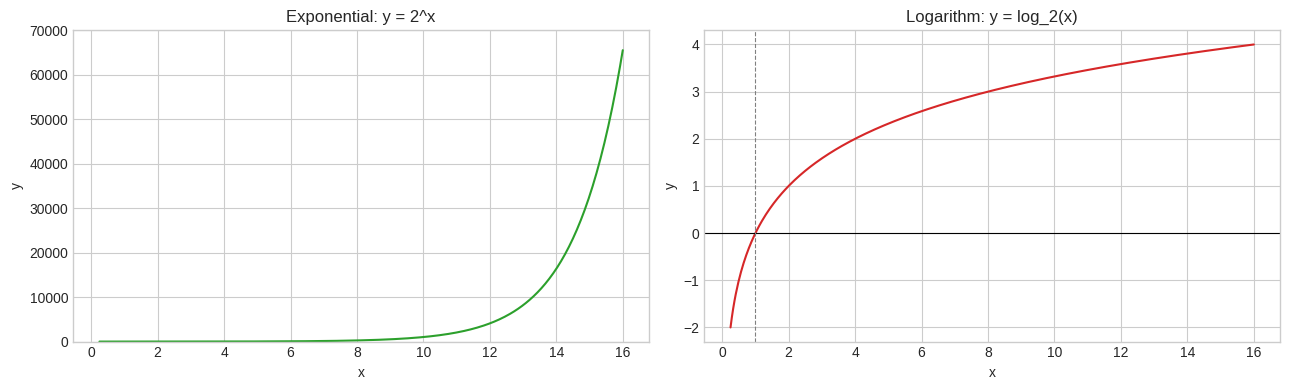

In [4]:
x_values = np.linspace(0.25, 16, 400)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(x_values, 2**x_values, color='tab:green')
axes[0].set_title('Exponential: y = 2^x')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_ylim(0, 70000)

axes[1].plot(x_values, np.log2(x_values), color='tab:red')
axes[1].set_title('Logarithm: y = log_2(x)')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].axvline(1, color='gray', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.show()

## 4. Natural log intuition

The natural log is not a different kind of logarithm. It is just the logarithm with base $e$:

$$\ln(x) = \log_e(x)$$

So the same intuition still applies:

> $\ln(x)$ asks: how many multiplicative steps of size $e$ does it take to get from $1$ to $x$?

That means:

- $\ln(1) = 0$ because no steps are needed to stay at $1$
- $\ln(e) = 1$ because one step of size $e$ gets you to $e$
- $\ln(e^k) = k$ because $k$ steps of size $e$ get you to $e^k$

### Why does $\ln$ feel special?

Because base $e$ is the most natural base for continuous growth. In calculus, $e^x$ is the exponential function whose growth rate matches its current size, and $\ln(x)$ is its inverse.

### What does this have to do with change of base?

Everything. The change-of-base rule says:

$$\log_b(x) = \frac{\ln(x)}{\ln(b)}$$

So $\ln$ can be used as a universal measuring stick:

- $\ln(x)$ measures the size of $x$ in natural-log units
- $\ln(b)$ measures the size of one base-$b$ step in those same units
- dividing converts natural-log units into base-$b$ units

So a good mental picture is:

> every logarithm is just a rescaled version of the natural log.

For example,

$$\log_2(8) = \frac{\ln(8)}{\ln(2)} = 3$$

So yes: the natural log is deeply connected to the change-of-base rule. It is the standard scale from which other log scales can be built.

In [2]:
import math
import pandas as pd

values_to_compare = [2, 8, math.e, 16]

ln_frame = pd.DataFrame({
    'x': values_to_compare,
    'ln(x)': [math.log(value) for value in values_to_compare],
    'log_2(x) from ln': [math.log(value) / math.log(2) for value in values_to_compare],
    'direct log_2(x)': [math.log(value, 2) for value in values_to_compare],
})

ln_frame

,x,ln(x),log_2(x) from ln,direct log_2(x)
0,2.000000,0.693147,1.000000,1.000000
1,8.000000,2.079442,3.000000,3.000000
2,2.718282,1.000000,1.442695,1.442695
3,16.000000,2.772589,4.000000,4.000000


## 4. Compact mental picture to remember

When you see a logarithm, translate it mentally as:

> **"What exponent would produce this number?"**

or, even more visually:

> **"How many equal multiplicative jumps of size base $b$ does it take to land on $x$?"**

From that one sentence, the rules become easy to remember:

- multiply numbers -> add log counts
- raise to a power -> multiply the log count
- $1$ means zero jumps
- the base itself means one jump
- change of base means changing the unit used to count jumps

If you want, the next step can be to add one more section to this notebook showing these rules on a single diagram with arrows between exponentials and logarithms.